<a href="https://colab.research.google.com/github/samanta-muskan/PRODIGY_ML_01/blob/main/Food_Recognition_Calorie_Estimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (4).zip to archive (4).zip


In [ ]:
import zipfile
from pathlib import Path

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload the dataset ZIP file.")

zip_path = zip_files[0]
extract_dir = "/content/indian_food_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Dataset extracted to:", extract_dir)

Dataset extracted to: /content/indian_food_dataset


In [ ]:
from pathlib import Path

root = Path("/content/indian_food_dataset")

for path in list(root.iterdir())[:30]:
    print(path.name, "—", "folder" if path.is_dir() else "file")

Indian Food Images — folder
List of Indian Foods.txt — file


In [ ]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

for folder in root.rglob("*"):
    if folder.is_dir():
        count = sum(
            1 for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        )

        if count > 0:
            print(f"{folder.relative_to(root)}: {count} images")

Indian Food Images/Indian Food Images/anarsa: 50 images
Indian Food Images/Indian Food Images/lassi: 50 images
Indian Food Images/Indian Food Images/dal_tadka: 50 images
Indian Food Images/Indian Food Images/bhatura: 50 images
Indian Food Images/Indian Food Images/chana_masala: 50 images
Indian Food Images/Indian Food Images/basundi: 50 images
Indian Food Images/Indian Food Images/gavvalu: 50 images
Indian Food Images/Indian Food Images/navrattan_korma: 50 images
Indian Food Images/Indian Food Images/kuzhi_paniyaram: 50 images
Indian Food Images/Indian Food Images/dum_aloo: 50 images
Indian Food Images/Indian Food Images/karela_bharta: 50 images
Indian Food Images/Indian Food Images/modak: 50 images
Indian Food Images/Indian Food Images/kofta: 50 images
Indian Food Images/Indian Food Images/poha: 50 images
Indian Food Images/Indian Food Images/aloo_matar: 50 images
Indian Food Images/Indian Food Images/kachori: 50 images
Indian Food Images/Indian Food Images/naan: 50 images
Indian Food

In [ ]:
from pathlib import Path

DATA_ROOT = Path("/content/indian_food_dataset")
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

image_folders = []

for folder in DATA_ROOT.rglob("*"):
    if folder.is_dir():
        count = sum(
            1 for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in image_extensions
        )

        if count > 0:
            image_folders.append((folder, count))

print("Folders containing images:", len(image_folders))

for folder, count in image_folders[:50]:
    print(f"{folder}: {count} images")

Folders containing images: 80
/content/indian_food_dataset/Indian Food Images/Indian Food Images/anarsa: 50 images
/content/indian_food_dataset/Indian Food Images/Indian Food Images/lassi: 50 images
/content/indian_food_dataset/Indian Food Images/Indian Food Images/dal_tadka: 50 images
/content/indian_food_dataset/Indian Food Images/Indian Food Images/bhatura: 50 images
/content/indian_food_dataset/Indian Food Images/Indian Food Images/chana_masala: 50 images
/content/indian_food_dataset/Indian Food Images/Indian Food Images/basundi: 50 images
/content/indian_food_dataset/Indian Food Images/Indian Food Images/gavvalu: 50 images
/content/indian_food_dataset/Indian Food Images/Indian Food Images/navrattan_korma: 50 images
/content/indian_food_dataset/Indian Food Images/Indian Food Images/kuzhi_paniyaram: 50 images
/content/indian_food_dataset/Indian Food Images/Indian Food Images/dum_aloo: 50 images
/content/indian_food_dataset/Indian Food Images/Indian Food Images/karela_bharta: 50 imag

In [ ]:
for folder, count in image_folders:
    print("Possible food class:", folder.name, "| Images:", count)

Possible food class: anarsa | Images: 50
Possible food class: lassi | Images: 50
Possible food class: dal_tadka | Images: 50
Possible food class: bhatura | Images: 50
Possible food class: chana_masala | Images: 50
Possible food class: basundi | Images: 50
Possible food class: gavvalu | Images: 50
Possible food class: navrattan_korma | Images: 50
Possible food class: kuzhi_paniyaram | Images: 50
Possible food class: dum_aloo | Images: 50
Possible food class: karela_bharta | Images: 50
Possible food class: modak | Images: 50
Possible food class: kofta | Images: 50
Possible food class: poha | Images: 50
Possible food class: aloo_matar | Images: 50
Possible food class: kachori | Images: 50
Possible food class: naan | Images: 50
Possible food class: jalebi | Images: 50
Possible food class: ras_malai | Images: 50
Possible food class: malapua | Images: 50
Possible food class: ariselu | Images: 50
Possible food class: palak_paneer | Images: 50
Possible food class: rabri | Images: 50
Possible f

In [ ]:
from pathlib import Path

DATA_DIR = Path(
    "/content/indian_food_dataset/Indian Food Images/Indian Food Images"
)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

class_counts = {}

for class_dir in sorted(DATA_DIR.iterdir()):
    if class_dir.is_dir():
        count = sum(
            1 for f in class_dir.iterdir()
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        )
        if count > 0:
            class_counts[class_dir.name] = count

print("Number of food classes:", len(class_counts))
print("Total images:", sum(class_counts.values()))
print("Minimum images per class:", min(class_counts.values()))
print("Maximum images per class:", max(class_counts.values()))

print("\nFood categories:")
print(list(class_counts.keys()))

Number of food classes: 80
Total images: 4000
Minimum images per class: 50
Maximum images per class: 50

Food categories:
['adhirasam', 'aloo_gobi', 'aloo_matar', 'aloo_methi', 'aloo_shimla_mirch', 'aloo_tikki', 'anarsa', 'ariselu', 'bandar_laddu', 'basundi', 'bhatura', 'bhindi_masala', 'biryani', 'boondi', 'butter_chicken', 'chak_hao_kheer', 'cham_cham', 'chana_masala', 'chapati', 'chhena_kheeri', 'chicken_razala', 'chicken_tikka', 'chicken_tikka_masala', 'chikki', 'daal_baati_churma', 'daal_puri', 'dal_makhani', 'dal_tadka', 'dharwad_pedha', 'doodhpak', 'double_ka_meetha', 'dum_aloo', 'gajar_ka_halwa', 'gavvalu', 'ghevar', 'gulab_jamun', 'imarti', 'jalebi', 'kachori', 'kadai_paneer', 'kadhi_pakoda', 'kajjikaya', 'kakinada_khaja', 'kalakand', 'karela_bharta', 'kofta', 'kuzhi_paniyaram', 'lassi', 'ledikeni', 'litti_chokha', 'lyangcha', 'maach_jhol', 'makki_di_roti_sarson_da_saag', 'malapua', 'misi_roti', 'misti_doi', 'modak', 'mysore_pak', 'naan', 'navrattan_korma', 'palak_paneer', 'pa

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

records = []

for label in sorted(class_counts.keys()):
    class_dir = DATA_DIR / label

    for file in class_dir.iterdir():
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "filepath": str(file),
                "label": label
            })

df = pd.DataFrame(records)

# 70% training, 30% temporary data
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# Split the temporary data equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining classes:", train_df["label"].nunique())
print("Validation classes:", val_df["label"].nunique())
print("Testing classes:", test_df["label"].nunique())

Training images: 2800
Validation images: 600
Testing images: 600

Training classes: 80
Validation classes: 80
Testing classes: 80


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

class_names = sorted(df["label"].unique())
class_to_index = {name: i for i, name in enumerate(class_names)}

def load_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)
    return image, label

def create_dataset(dataframe, training=False):
    paths = dataframe["filepath"].to_numpy()
    labels = dataframe["label"].map(class_to_index).to_numpy()

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Datasets are ready!")

Datasets are ready!


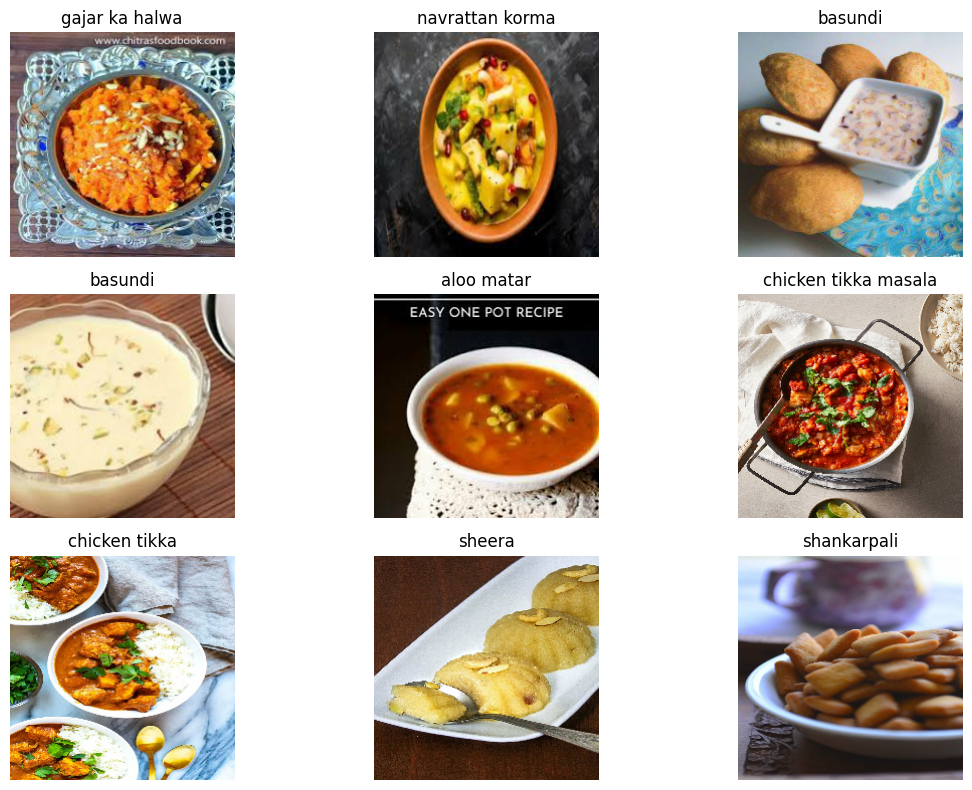

In [ ]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)

        # Convert pixels back approximately for display
        display_image = (images[i].numpy() + 1.0) / 2.0
        plt.imshow(display_image.clip(0, 1))

        label_index = int(labels[i].numpy())
        plt.title(class_names[label_index].replace("_", " "))
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras import layers, models

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Initially freeze the pretrained layers
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 80)             │       102,480 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,360,464 (9.00 MB)

 Trainable params: 102,480 (400.31 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("/content/food_recognition_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(OUTPUT_DIR / "best_food_model.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks
)

Epoch 1/12
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.0606 - loss: 4.4401
Epoch 1: val_accuracy improved from None to 0.29833, saving model to /content/food_recognition_output/best_food_model.keras

Epoch 1: finished saving model to /content/food_recognition_output/best_food_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 40s 301ms/step - accuracy: 0.1246 - loss: 3.8836 - val_accuracy: 0.2983 - val_loss: 2.7765 - learning_rate: 0.0010
Epoch 2/12
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.4212 - loss: 2.2798
Epoch 2: val_accuracy improved from 0.29833 to 0.42667, saving model to /content/food_recognition_output/best_food_model.keras

Epoch 2: finished saving model to /content/food_recognition_output/best_food_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 115ms/step - accuracy: 0.4579 - loss: 2.1321 - val_accuracy: 0.4267 - val_loss: 2.2528 - learning_rate: 0.0010
Epoch 3/12
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.6151 - loss: 1.5544
Epoch 3: val_accuracy improve

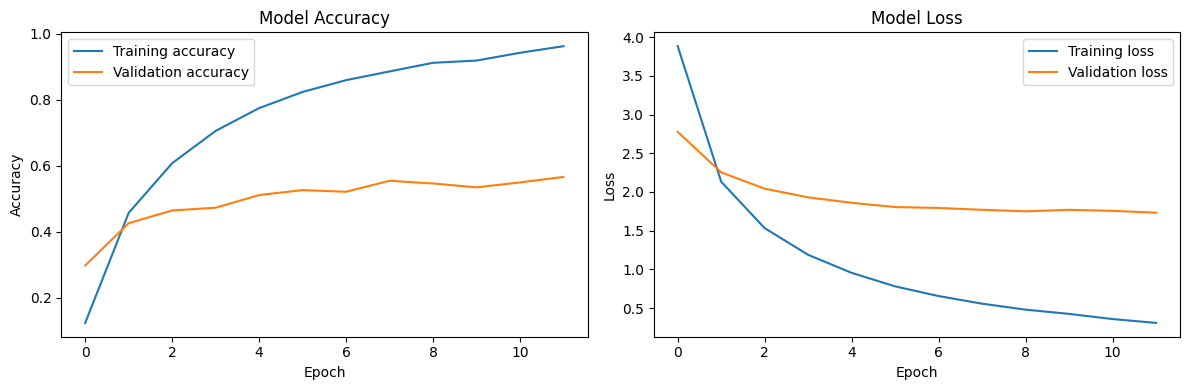

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_model = tf.keras.models.load_model(
    str(OUTPUT_DIR / "best_food_model.keras")
)

test_loss, test_accuracy = best_model.evaluate(test_ds)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 10s 191ms/step - accuracy: 0.5767 - loss: 1.6399
Test loss: 1.6399
Test accuracy: 57.67%


In [ ]:
with open(OUTPUT_DIR / "class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

print("Model and class labels saved successfully.")
print("Model:", OUTPUT_DIR / "best_food_model.keras")
print("Labels:", OUTPUT_DIR / "class_names.json")

Model and class labels saved successfully.
Model: /content/food_recognition_output/best_food_model.keras
Labels: /content/food_recognition_output/class_names.json


Saving 1dbc60a00c.jpg to 1dbc60a00c.jpg


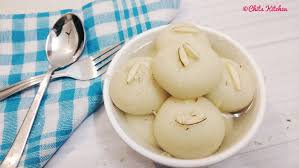


Predicted food: Rasgulla
Model confidence: 93.48%

Top 3 predictions:
Rasgulla: 93.48%
Cham Cham: 6.00%
Ras Malai: 0.19%


In [ ]:
from google.colab import files
from IPython.display import display
from PIL import Image
import numpy as np
import tensorflow as tf
import json
import matplotlib.pyplot as plt

# Load the trained model and labels
model = tf.keras.models.load_model(
    "/content/food_recognition_output/best_food_model.keras"
)

with open(
    "/content/food_recognition_output/class_names.json",
    "r"
) as f:
    class_names = json.load(f)

# Upload a food image
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload a food image.")

image_path = next(iter(uploaded))

# Prepare the image
image = Image.open(image_path).convert("RGB")
display(image)

resized = image.resize((224, 224))
image_array = np.array(resized, dtype=np.float32)
image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
    image_array
)
image_array = np.expand_dims(image_array, axis=0)

# Predict
predictions = model.predict(image_array, verbose=0)[0]
top_indices = np.argsort(predictions)[-3:][::-1]

predicted_index = int(top_indices[0])
predicted_food = class_names[predicted_index]
confidence = float(predictions[predicted_index])

print("\nPredicted food:", predicted_food.replace("_", " ").title())
print(f"Model confidence: {confidence:.2%}")

print("\nTop 3 predictions:")
for index in top_indices:
    print(
        f"{class_names[index].replace('_', ' ').title()}: "
        f"{predictions[index]:.2%}"
    )

In [ ]:
import pandas as pd

nutrition_data = {
    "biryani": {"kcal_per_100g": 180},
    "chapati": {"kcal_per_100g": 297},
    "dal_tadka": {"kcal_per_100g": 130},
    "dal_makhani": {"kcal_per_100g": 180},
    "dosa": {"kcal_per_100g": 168},
    "idli": {"kcal_per_100g": 146},
    "poha": {"kcal_per_100g": 130},
    "chana_masala": {"kcal_per_100g": 160},
    "palak_paneer": {"kcal_per_100g": 170},
    "paneer_butter_masala": {"kcal_per_100g": 220},
    "butter_chicken": {"kcal_per_100g": 190},
    "gulab_jamun": {"kcal_per_100g": 350},
    "jalebi": {"kcal_per_100g": 400},
    "lassi": {"kcal_per_100g": 100},
}

nutrition_df = pd.DataFrame([
    {
        "food": food,
        "kcal_per_100g": values["kcal_per_100g"]
    }
    for food, values in nutrition_data.items()
])

display(nutrition_df)

,food,kcal_per_100g
0,biryani,180
1,chapati,297
2,dal_tadka,130
3,dal_makhani,180
4,dosa,168
5,idli,146
6,poha,130
7,chana_masala,160
8,palak_paneer,170
9,paneer_butter_masala,220


In [ ]:
food_key = predicted_food.lower().strip()

if food_key not in nutrition_data:
    print(
        f"No nutrition entry yet for {predicted_food.replace('_', ' ')}."
    )
    print("Add a verified value to nutrition_data before estimating calories.")
else:
    serving_weight_g = float(
        input("Enter the serving weight in grams (e.g. 150): ")
    )

    if serving_weight_g <= 0:
        raise ValueError("Serving weight must be greater than zero.")

    kcal_per_100g = nutrition_data[food_key]["kcal_per_100g"]
    estimated_calories = kcal_per_100g * serving_weight_g / 100

    print("Food:", predicted_food.replace("_", " ").title())
    print(f"Serving weight: {serving_weight_g:.0f} g")
    print(f"Estimated calories: {estimated_calories:.0f} kcal")
    print("Note: Estimate only; actual calories depend on the recipe.")

No nutrition entry yet for rasgulla.
Add a verified value to nutrition_data before estimating calories.


In [ ]:
from google.colab import files

files.download(
    "/content/food_recognition_output/best_food_model.keras"
)

files.download(
    "/content/food_recognition_output/class_names.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>